In [1]:
import torch
import torchvision
import matplotlib.pyplot as plt

from PIL import Image
from models import *
from cont_IBISA import *
from utils import *

In [2]:
if torch.cuda.is_available():
    device = torch.device('cuda:0')
else:
    device = torch.device('cpu')

torch.manual_seed(0)

transform = torchvision.transforms.Compose([transforms.Resize((224,224)),
                            transforms.ToTensor()])

In [ ]:
architecture = 'ResNET'

if architecture == 'VGG':
    model = VGG_emb()
    model = model.to(device)
    model.eval()
elif architecture == 'ResNET':
    model = ResNET_emb()
    model = model.to(device)
    model.eval()


In [4]:
pil_img1 = Image.open('./test_images/Black1.JPEG').convert('RGB')
pil_img2 = Image.open('./test_images/Black2.JPEG').convert('RGB')

img1 = transform(pil_img1)

x1 = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])(img1)
x1 = x1[None,...].to(device)


In [5]:
p = []
patches_list = patch_image(pil_img=pil_img2, grid_size=3)

for i,target_patch in enumerate(patches_list):
    img2 = transform(target_patch)

    x2 = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])(img2)
    x2 = x2[None,...].to(device)

    p.append(compute_saliency(x=x1, x_target=x2, model=model, n_masks=20))

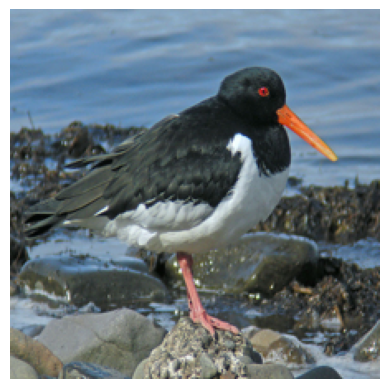

In [6]:
plt.imshow(pil_img2.resize((224,224)))
plt.axis('off')
plt.show()

(-0.5, 223.5, 223.5, -0.5)

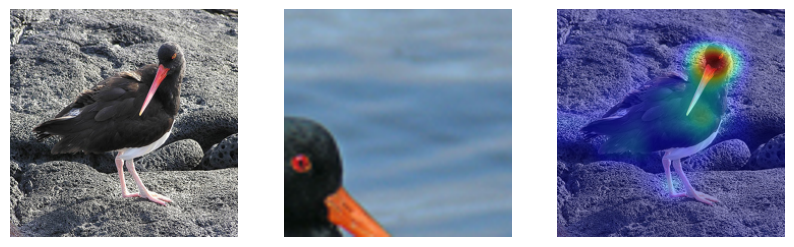

In [12]:
f, ax = plt.subplots(1,3,figsize=(10,6))
i = 2

ax[0].imshow(pil_img1.resize((224,224)))
ax[0].axis('off')

ax[1].imshow(patches_list[i])
ax[1].axis('off')

ax[2].imshow(pil_img1.resize((224,224)))
ax[2].imshow(p[i], cmap='jet', alpha=0.4)
ax[2].axis('off')


(-0.5, 223.5, 223.5, -0.5)

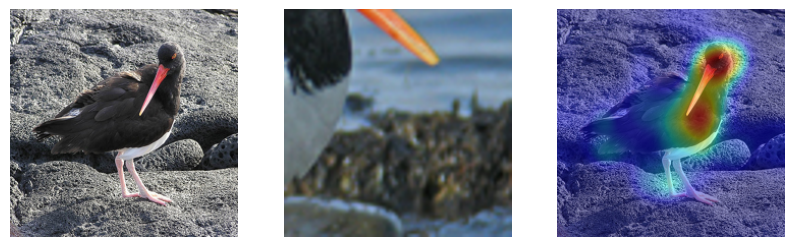

In [15]:
f, ax = plt.subplots(1,3,figsize=(10,6))
i = 5

ax[0].imshow(pil_img1.resize((224,224)))
ax[0].axis('off')

ax[1].imshow(patches_list[i])
ax[1].axis('off')

ax[2].imshow(pil_img1.resize((224,224)))
ax[2].imshow(p[i], cmap='jet', alpha=0.4)
ax[2].axis('off')

(-0.5, 223.5, 223.5, -0.5)

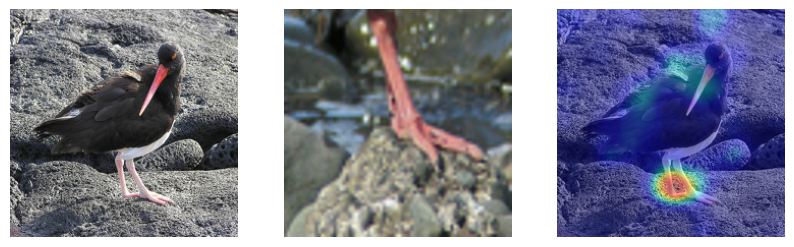

In [18]:
f, ax = plt.subplots(1,3,figsize=(10,6))
i = 7

ax[0].imshow(pil_img1.resize((224,224)))
ax[0].axis('off')

ax[1].imshow(patches_list[i])
ax[1].axis('off')

ax[2].imshow(pil_img1.resize((224,224)))
ax[2].imshow(p[i], cmap='jet', alpha=0.4)
ax[2].axis('off')

(-0.5, 223.5, 223.5, -0.5)

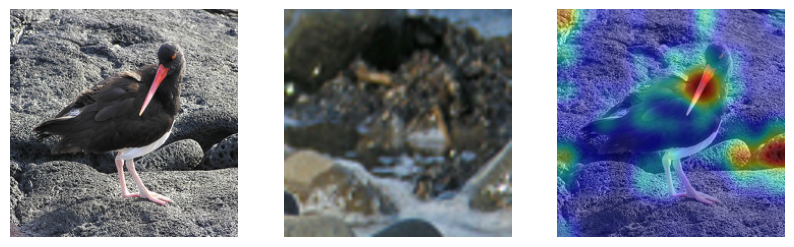

In [19]:
f, ax = plt.subplots(1,3,figsize=(10,6))
i = 8

ax[0].imshow(pil_img1.resize((224,224)))
ax[0].axis('off')

ax[1].imshow(patches_list[i])
ax[1].axis('off')

ax[2].imshow(pil_img1.resize((224,224)))
ax[2].imshow(p[i], cmap='jet', alpha=0.4)
ax[2].axis('off')